In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf
from sklearn.datasets import load_iris
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    accuracy_score,
    confusion_matrix,
    precision_score,
    recall_score,
    f1_score
)

In [4]:
dataset = load_iris()
X = dataset.data
y = dataset.target
print(f"No. of samples: {X.shape[0]}")
print(f"No. of features: {X.shape[1]}")

print(f"Class distribution: \n")
for i in np.unique(y):
  print(f"{dataset.target_names[i]}: {np.sum(y==i)}")

print(f"Features name: {dataset.feature_names}")

No. of samples: 150
No. of features: 4
Class distribution: 

setosa: 50
versicolor: 50
virginica: 50
Features name: ['sepal length (cm)', 'sepal width (cm)', 'petal length (cm)', 'petal width (cm)']


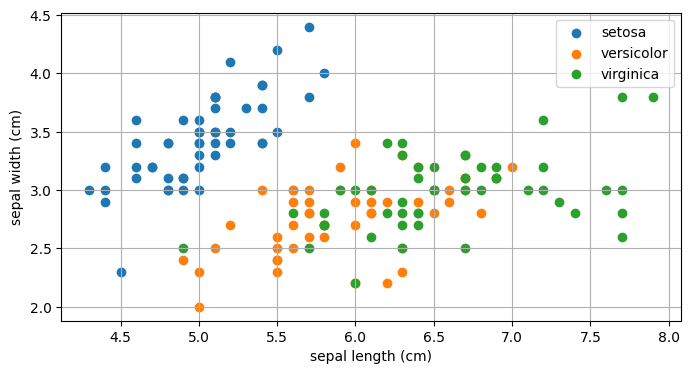

In [10]:
plt.figure(figsize=(8, 4))
plt.scatter(X[y==0, 0], X[y==0, 1], label=f'{dataset.target_names[0]}')
plt.scatter(X[y==1, 0], X[y==1, 1], label=f'{dataset.target_names[1]}')
plt.scatter(X[y==2, 0], X[y==2, 1], label=f'{dataset.target_names[2]}')
plt.xlabel(f"{dataset.feature_names[0]}")
plt.ylabel(f"{dataset.feature_names[1]}")
plt.grid()
plt.legend()
plt.show()

In [11]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=42
)

scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

In [12]:
class DropConnect(tf.keras.layers.Dense):
  def __init__(self, units, rate=0.0, **kwargs):
    super().__init__(units, **kwargs)
    self.rate = rate
  def call(self, inputs, training=None):
    kernel = self.kernel
    if training and self.rate>0.0:
      mask = tf.cast(
          tf.random.uniform(tf.shape(kernel)) > self.kernel,
          kernel.dtype
      )
      kernel = kernel * mask / (1-self.rate)
    output = tf.matmul(inputs, kernel) + self.bias
    return self.activation(output)


In [22]:
def build_model_original(lr=0.001):
  model = tf.keras.Sequential([
      tf.keras.layers.Input(shape=(4,)),
      tf.keras.layers.Dense(8, activation='relu'),
      tf.keras.layers.Dense(3, activation='softmax')
  ])
  model.compile(
      optimizer=tf.keras.optimizers.Adam(learning_rate=lr),
      loss=tf.keras.losses.SparseCategoricalCrossentropy(),
      metrics=['accuracy']
  )
  return model

In [21]:
def build_model(lr=0.001, node_rate=0.0, connect_rate=0.0):
  model = tf.keras.Sequential([
      tf.keras.layers.Input(shape=(4,)),
      tf.keras.layers.Dropout(node_rate),
      DropConnect(16, rate=connect_rate, activation='relu'),
      tf.keras.layers.Dense(8, activation='relu'),
      tf.keras.layers.Dense(3, activation='softmax')
  ])
  model.compile(
      optimizer=tf.keras.optimizers.Adam(learning_rate=lr),
      loss=tf.keras.losses.SparseCategoricalCrossentropy(),
      metrics=['accuracy']
  )
  return model

In [19]:
def evaluate(model):
  predict = np.argmax(model.predict(X_test, verbose=1), axis=1)
  return [
      accuracy_score(y_test, predict),
      precision_score(y_test, predict, average='macro', zero_division=0),
      recall_score(y_test, predict, average='macro', zero_division=0),
      f1_score(y_test, predict, average='macro', zero_division=0)
  ]

In [24]:
result = []
losses = {}

for lr in [0.001, 0.01, 0.1]:
  model = build_model_original(lr=lr)
  history = model.fit(X_train, y_train, epochs=100, verbose=0, batch_size=32)
  losses[lr] = history.history['loss']

  result.append([lr] + evaluate(model))

print("Learning Rate Results\n")
print(pd.DataFrame(result, columns=[
    'learning rate', 'accuracy', 'precision', 'recall', 'f1 score'
]))

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 95ms/step


1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 243ms/step


1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 64ms/step
Learning Rate Results

   learning rate  accuracy  precision    recall  f1 score
0          0.001  0.800000   0.875000  0.800000  0.780220
1          0.010  0.966667   0.969697  0.966667  0.966583
2          0.100  0.933333   0.933333  0.933333  0.933333


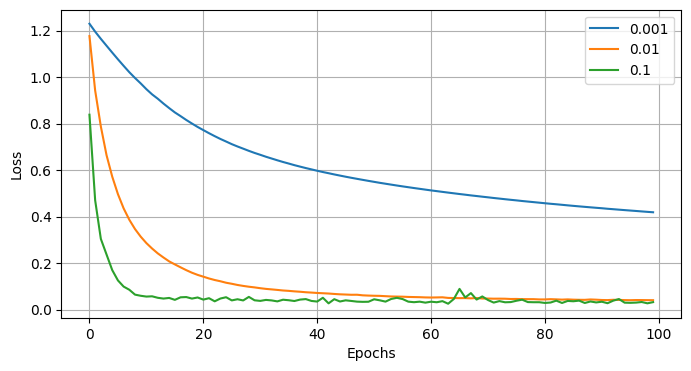

In [25]:
plt.figure(figsize=(8,4))
for lr in losses:
  plt.plot(losses[lr], label=str(lr))
plt.xlabel("Epochs")
plt.ylabel("Loss")
plt.grid()
plt.legend()
plt.show()

In [26]:
results = []

for node_rate in [0.0, 0.2, 0.4]:
  model = build_model(lr=0.01, node_rate=node_rate)
  model.fit(X_train, y_train, epochs=100, verbose=0, batch_size=32)
  results.append([node_rate]+evaluate(model))

print("Dropout Results\n")
print(pd.DataFrame(results, columns=[
    'dropout rate', 'accuracy', 'precision', 'recall', 'f1 score'
]))

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 143ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 72ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 70ms/step
Dropout Results

   dropout rate  accuracy  precision    recall  f1 score
0           0.0  0.966667   0.969697  0.966667  0.966583
1           0.2  0.900000   0.923077  0.900000  0.897698
2           0.4  0.866667   0.904762  0.866667  0.861111


In [27]:
results = []

for connect_rate in [0.0, 0.2, 0.4]:
  model = build_model(lr=0.01, connect_rate=connect_rate)
  model.fit(X_train, y_train, epochs=100, verbose=0, batch_size=32)
  results.append([connect_rate]+evaluate(model))

print("DropConnect Results\n")
print(pd.DataFrame(results, columns=[
    'connect rate', 'accuracy', 'precision', 'recall', 'f1 score'
]))

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 70ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 66ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 100ms/step
DropConnect Results

   connect rate  accuracy  precision    recall  f1 score
0           0.0  0.966667   0.969697  0.966667  0.966583
1           0.2  0.933333   0.933333  0.933333  0.933333
2           0.4  0.900000   0.923077  0.900000  0.897698
